
# PRAICP-1001 — Gender Detection Using Deep Learning

## 1. Business Understanding

### Problem Statement
Develop a machine learning model to classify facial images into the two categories provided by the dataset: man and woman.

### Project Objectives
1. Perform image preprocessing.
2. Develop a machine learning model for image classification.
3. Evaluate the model's classification performance.
4. Save the best-performing model.

### Proposed Approach
- Explore the image dataset.
- Resize and normalize images.
- Split the dataset into training, validation and testing sets.
- Apply data augmentation.
- Train a Convolutional Neural Network (CNN).
- Evaluate and improve model performance.

### Expected Outcome
A trained image classification model that predicts one of the two dataset labels for an input facial image.

**Limitation:** Facial appearance cannot reliably establish a person's gender identity.


In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import tensorflow as tf


In [2]:
dataset_path = Path(r"/content/drive/MyDrive/Gender_detection/PRAICP-1001-GenderDetc/Data/gender_dataset_face")
print("Dataset exists:", dataset_path.exists())

Dataset exists: True


In [3]:
if dataset_path.exists():
    print("Available classes:",
          [folder.name for folder in dataset_path.iterdir()
           if folder.is_dir()])

Available classes: ['woman', 'man']



## 2. Exploratory Data Analysis (EDA)

### Objective
- Count the number of images in each class.
- Identify class imbalance.
- Examine image dimensions.
- Visualize sample images.
- Identify corrupted or unsupported image files.


In [4]:

# Define supported image formats
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Count images in each class
class_counts = {}

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        images = [
            file for file in folder.rglob("*")
            if file.is_file()
            and file.suffix.lower() in image_extensions
        ]

        class_counts[folder.name] = len(images)

# Convert results into a DataFrame
df_counts = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image_Count"]
)

print(df_counts)
print("\nTotal Images:", df_counts["Image_Count"].sum())


   Class  Image_Count
0    man         1173
1  woman         1134

Total Images: 2307


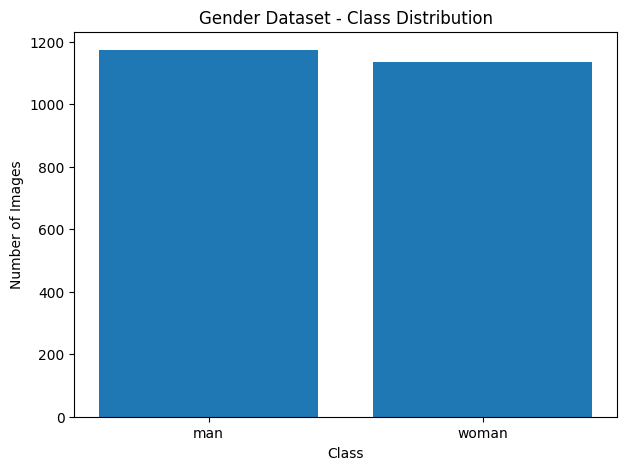

In [5]:

plt.figure(figsize=(7, 5))

plt.bar(
    df_counts["Class"],
    df_counts["Image_Count"]
)

plt.title("Gender Dataset - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()



### Sample Image Visualization

Objective:
- Display sample images from both classes.
- Understand facial image quality and variations.
- Observe differences in image sizes, lighting,
  backgrounds and facial orientation.


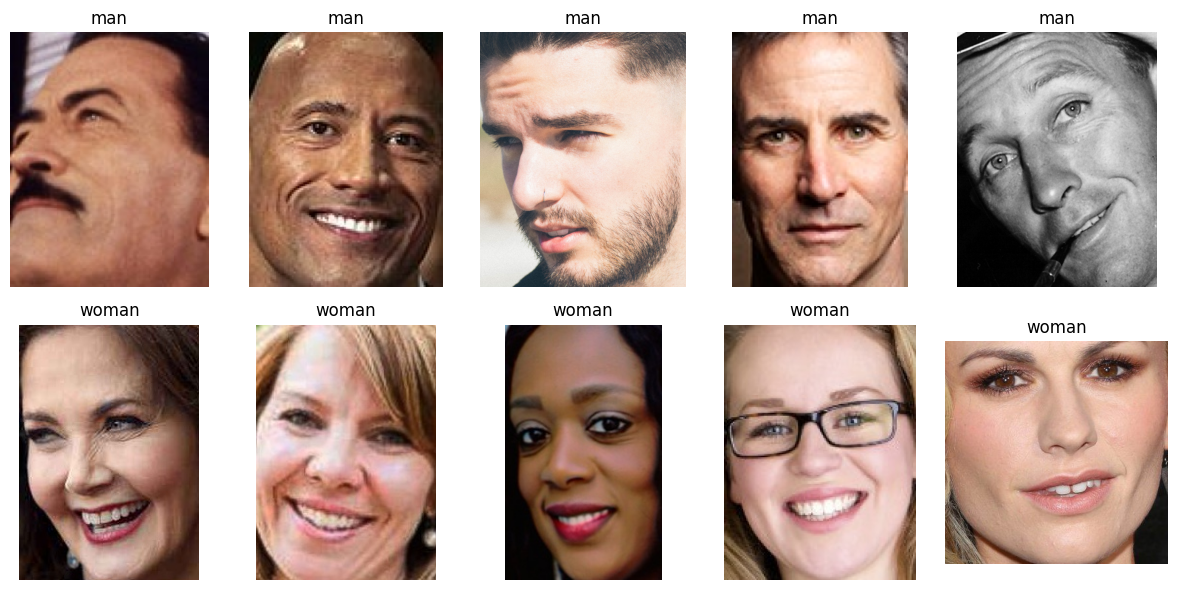

In [6]:

import random

plt.figure(figsize=(12, 6))

classes = ["man", "woman"]

for i, class_name in enumerate(classes):

    folder = dataset_path / class_name

    image_files = [
        f for f in folder.rglob("*")
        if f.suffix.lower() in image_extensions
    ]

    sample_images = random.sample(
        image_files,
        min(5, len(image_files))
    )

    for j, image_path in enumerate(sample_images):

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        plt.subplot(2, 5, i * 5 + j + 1)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()



### Image Quality and Dimension Analysis

Objectives:
1. Identify image dimensions and color modes.
2. Detect corrupted or unreadable images.
3. Examine variation in image resolution.
4. Determine suitable preprocessing requirements.


In [7]:

image_info = []
corrupted_images = []

for class_name in ["man", "woman"]:

    folder = dataset_path / class_name

    for image_path in folder.rglob("*"):

        if image_path.suffix.lower() not in image_extensions:
            continue

        try:
            with Image.open(image_path) as img:
                width, height = img.size
                mode = img.mode
                img.verify()

            image_info.append({
                "Class": class_name,
                "Width": width,
                "Height": height,
                "Mode": mode
            })

        except Exception:
            corrupted_images.append(str(image_path))

df_images = pd.DataFrame(image_info)

print("Total Valid Images:", len(df_images))
print("Corrupted Images:", len(corrupted_images))

print("\nImage Dimensions Summary:")
print(df_images[["Width", "Height"]].describe())

print("\nImage Color Modes:")
print(df_images["Mode"].value_counts())


Total Valid Images: 2307
Corrupted Images: 0

Image Dimensions Summary:
             Width       Height
count  2307.000000  2307.000000
mean    203.317729   270.235804
std     168.555876   222.478606
min      24.000000    25.000000
25%     112.000000   149.000000
50%     160.000000   214.000000
75%     240.500000   320.000000
max    2269.000000  3068.000000

Image Color Modes:
Mode
RGB    2307
Name: count, dtype: int64



### Dataset Label Verification

Objective:
- Verify image labels against their source folders.
- Display sample images with their filenames.
- Identify possible labeling inconsistencies.
- Prevent incorrect labels from affecting model training.


man folder: 1173 images
woman folder: 1134 images


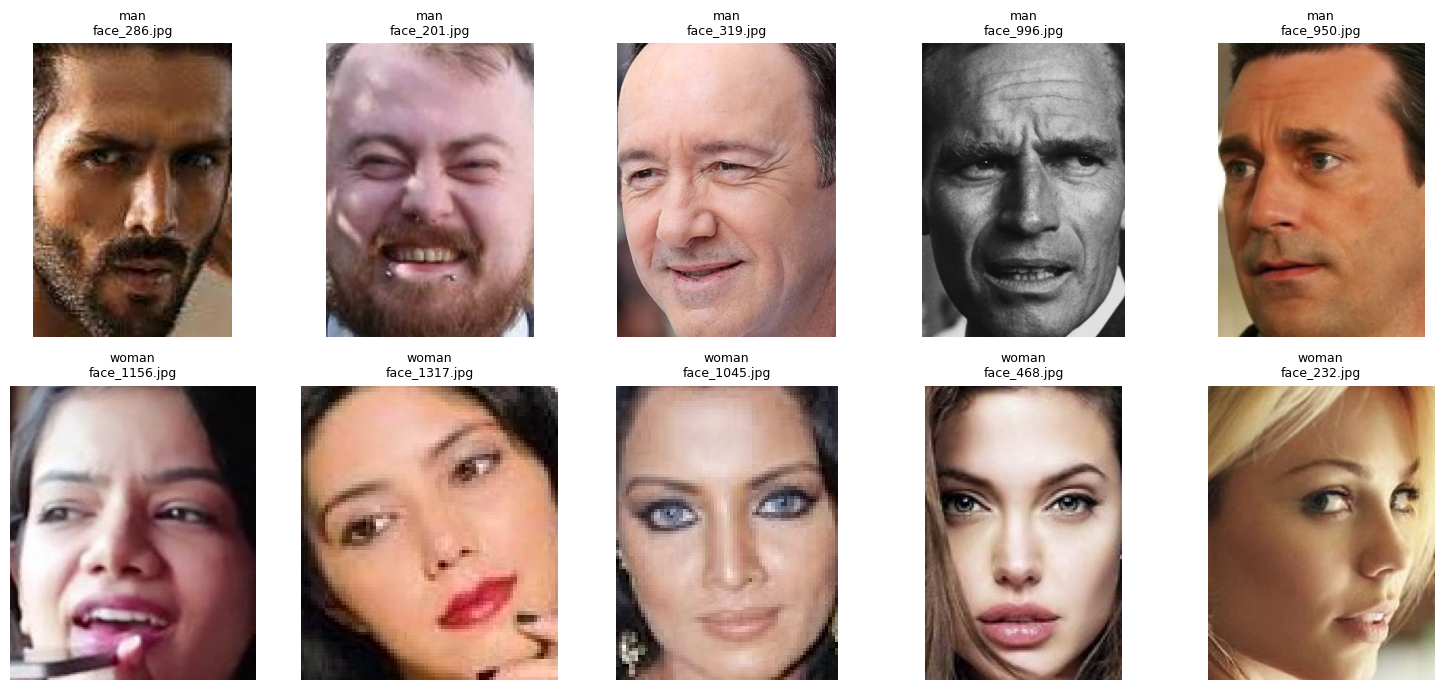

In [8]:

import random

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row, class_name in enumerate(["man", "woman"]):

    folder = dataset_path / class_name

    files = [
        f for f in folder.rglob("*")
        if f.is_file()
        and f.suffix.lower() in image_extensions
    ]

    print(class_name, "folder:", len(files), "images")

    samples = random.sample(files, min(5, len(files)))

    for col, file in enumerate(samples):

        with Image.open(file) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(
            f"{class_name}\n{file.name[:20]}",
            fontsize=9
        )

        axes[row, col].axis("off")

plt.tight_layout()
plt.show()



## 3. Data Preprocessing

### Dataset Splitting

The dataset contains 2,307 RGB facial images.

We will divide the dataset into:
- Training: 70%
- Validation: 15%
- Testing: 15%

Stratified splitting will preserve approximately
equal class proportions across the three datasets.

Preprocessing requirements:
1. Resize images to 224 × 224 pixels.
2. Convert images into numerical tensors.
3. Normalize pixel values where required.
4. Apply data augmentation only to training images.
5. Prepare datasets for CNN training.


In [9]:

from sklearn.model_selection import train_test_split

# Collect image paths and their numerical labels
image_paths = []
labels = []

class_mapping = {
    "man": 0,
    "woman": 1
}

for class_name, label in class_mapping.items():

    folder = dataset_path / class_name

    for file in folder.rglob("*"):

        if file.is_file() and file.suffix.lower() in image_extensions:
            image_paths.append(str(file))
            labels.append(label)

# First split: 70% training, 30% remaining
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: 15% validation, 15% testing
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Training Images:", len(train_paths))
print("Validation Images:", len(val_paths))
print("Testing Images:", len(test_paths))
print("Total Images:",
      len(train_paths) + len(val_paths) + len(test_paths))


Training Images: 1614
Validation Images: 346
Testing Images: 347
Total Images: 2307


In [10]:

from collections import Counter

print("Training:", Counter(train_labels))
print("Validation:", Counter(val_labels))
print("Testing:", Counter(test_labels))


Training: Counter({0: 821, 1: 793})
Validation: Counter({0: 176, 1: 170})
Testing: Counter({0: 176, 1: 171})



### Image Resizing and TensorFlow Dataset Creation

All images will be resized to 224 × 224 pixels.

Preprocessing steps:
1. Read image files.
2. Decode images into RGB tensors.
3. Resize images to 224 × 224.
4. Normalize pixel values from 0–255 to 0–1.
5. Prepare batches of 32 images.

The same resizing and normalization will be applied
to training, validation and testing datasets.


In [11]:

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def preprocess_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)

    image = image / 255.0

    return image, label


def create_dataset(paths, labels, training=False):

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    ds = ds.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds = create_dataset(
    train_paths, train_labels, training=True
)

val_ds = create_dataset(
    val_paths, val_labels
)

test_ds = create_dataset(
    test_paths, test_labels
)

print("TensorFlow datasets created successfully!")


TensorFlow datasets created successfully!



### Data Augmentation

Data augmentation is used to improve CNN generalization
and reduce overfitting.

Techniques:
- Random horizontal flipping
- Random rotation
- Random zoom

Augmentation is applied only during training.
Validation and testing images remain unchanged.


In [12]:

from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
])

print("Data augmentation created successfully!")


Data augmentation created successfully!



## 4. CNN Model Development

### Objective
Develop a Convolutional Neural Network (CNN) to classify
facial images into the two dataset categories:
- Man (0)
- Woman (1)

### CNN Architecture
1. Input Layer (224 × 224 × 3)
2. Data Augmentation
3. Convolutional Layers (Conv2D)
4. Max Pooling Layers
5. Global AveragePooling2D
6. Dense Layer
7. Dropout Layer
8. Output Layer (Sigmoid)

### Model Configuration
- Optimizer: Adam
- Loss Function: Binary Crossentropy
- Evaluation Metric: Accuracy


In [16]:

from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

cnn_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")


CNN model compiled successfully!



### CNN Model Training

The CNN model will be trained using the training dataset
and evaluated on the validation dataset.

Training configuration:
- Maximum epochs: 15
- Batch size: 32 (configured during preprocessing)
- Early stopping patience: 3
- Restore best model weights: Yes

The testing dataset will remain untouched until final
model evaluation.


In [22]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "/content/drive/MyDrive/Gender_detection/best_gender_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop, checkpoint]
)


Epoch 1/20
50/51 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9292 - loss: 0.1573
Epoch 1: val_loss improved from None to 0.22514, saving model to /content/drive/MyDrive/Gender_detection/best_gender_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Gender_detection/best_gender_cnn.keras
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - accuracy: 0.9356 - loss: 0.1512 - val_accuracy: 0.9075 - val_loss: 0.2251
Epoch 2/20
50/51 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9513 - loss: 0.1493
Epoch 2: val_loss improved from 0.22514 to 0.19348, saving model to /content/drive/MyDrive/Gender_detection/best_gender_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Gender_detection/best_gender_cnn.keras
51/51 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.9461 - loss: 0.1583 - val_accuracy: 0.9249 - val_loss: 0.1935
Epoch 3/20
50/51 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9331 - loss: 0.1897
Epoch 3: val_loss did not improve from 0.19348
51/51 ━━━━━━━━

In [23]:

from tensorflow.keras.models import load_model

best_model = load_model(
    "/content/drive/MyDrive/Gender_detection/best_gender_cnn.keras"
)

val_loss, val_accuracy = best_model.evaluate(val_ds)

print(f"Best Model Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Best Model Validation Loss: {val_loss:.4f}")


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.9249 - loss: 0.1935
Best Model Validation Accuracy: 92.49%
Best Model Validation Loss: 0.1935


In [24]:

test_loss, test_accuracy = cnn_model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step - accuracy: 0.9452 - loss: 0.1330
Test Accuracy: 94.52%
Test Loss: 0.1330


In [25]:

test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"Best Model Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Best Model Test Loss: {test_loss:.4f}")


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - accuracy: 0.9452 - loss: 0.1330
Best Model Test Accuracy: 94.52%
Best Model Test Loss: 0.1330



## 6. Final CNN Model Evaluation

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

The best saved CNN model is evaluated on the
previously unseen test dataset.

Class Labels:
- 0: Man
- 1: Woman


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step
Classification Report:
              precision    recall  f1-score   support

         Man       0.94      0.95      0.95       176
       Woman       0.95      0.94      0.94       171

    accuracy                           0.95       347
   macro avg       0.95      0.95      0.95       347
weighted avg       0.95      0.95      0.95       347



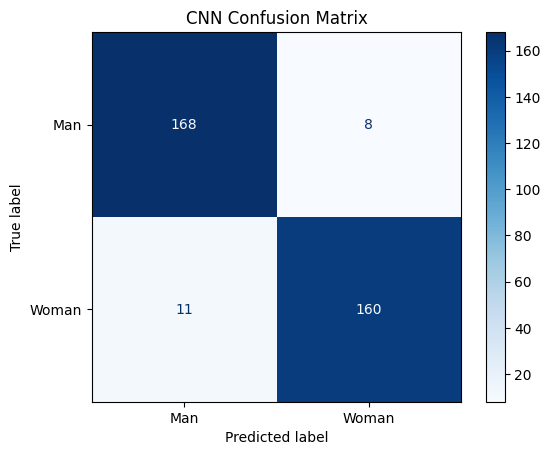

In [26]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Get predictions from the saved best model
y_true = np.array(test_labels)

y_prob = best_model.predict(test_ds).ravel()

y_pred = (y_prob >= 0.5).astype(int)

# Classification report
print("Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Man", "Woman"]
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Man", "Woman"]
)

disp.plot(cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.show()



## 8. External Image Testing

### Objective
Test the saved CNN model using two new images
that were not part of the training dataset.

### Procedure
1. Upload two external facial images.
2. Resize images to 224 × 224.
3. Normalize pixel values.
4. Predict using the saved CNN model.
5. Display predicted labels and probabilities.


In [28]:

from google.colab import files

uploaded = files.upload()


Saving test_man.jpg to test_man.jpg


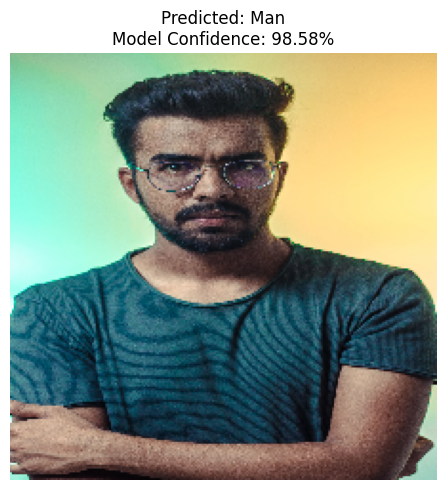

In [29]:

from tensorflow.keras.utils import load_img, img_to_array

class_names = ["Man", "Woman"]

plt.figure(figsize=(10, 5))

for i, filename in enumerate(uploaded.keys()):

    img = load_img(filename, target_size=(224, 224))

    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    probability = float(
        best_model.predict(img_array, verbose=0)[0][0]
    )

    predicted_class = class_names[int(probability >= 0.5)]
    confidence = max(probability, 1 - probability) * 100

    plt.subplot(1, len(uploaded), i + 1)
    plt.imshow(img)
    plt.title(
        f"Predicted: {predicted_class}\n"
        f"Model Confidence: {confidence:.2f}%"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [30]:

from google.colab import files

uploaded = files.upload()

Saving test_woman.jpg to test_woman.jpg


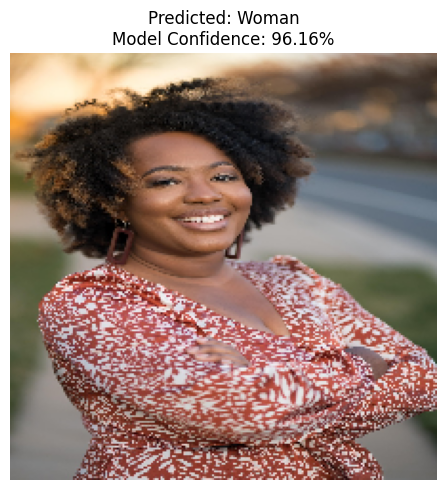

In [31]:
from tensorflow.keras.utils import load_img, img_to_array

class_names = ["Man", "Woman"]

plt.figure(figsize=(10, 5))

for i, filename in enumerate(uploaded.keys()):

    img = load_img(filename, target_size=(224, 224))

    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    probability = float(
        best_model.predict(img_array, verbose=0)[0][0]
    )

    predicted_class = class_names[int(probability >= 0.5)]
    confidence = max(probability, 1 - probability) * 100

    plt.subplot(1, len(uploaded), i + 1)
    plt.imshow(img)
    plt.title(
        f"Predicted: {predicted_class}\n"
        f"Model Confidence: {confidence:.2f}%"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()



# FINAL PROJECT SUMMARY AND CONCLUSION

## Project Details

**Project ID:** PRAICP-1001  
**Project Title:** Gender Detection Using CNN  
**Domain:** Artificial Intelligence / Computer Vision  
**Technique:** Deep Learning - Convolutional Neural Network  
**Framework:** TensorFlow / Keras  
**Platform:** Google Colab  

---

## 1. Business Problem

The objective of this project is to develop a deep
learning model that classifies facial images into
two predefined dataset categories: Man and Woman.

The system learns visual patterns from labeled
training images and predicts the corresponding
dataset category for unseen images.

---

## 2. Dataset Description

The dataset contains 2,307 facial images
organized into two classes.

| Class | Images |
|---|---:|
| Man (0) | 1,173 |
| Woman (1) | 1,134 |
| **Total** | **2,307** |

The dataset is approximately balanced.

### Dataset Splitting

| Dataset | Images | Percentage |
|---|---:|---:|
| Training | 1,614 | 70% |
| Validation | 346 | 15% |
| Testing | 347 | 15% |

Stratified sampling was used to maintain
class proportions across the datasets.

---

## 3. Data Preprocessing

The following preprocessing techniques
were implemented:

1. Image quality verification
2. Corrupted image detection
3. RGB image conversion
4. Image resizing to 224 × 224 pixels
5. Pixel normalization (0-1)
6. Dataset splitting
7. Data augmentation

### Data Augmentation

- Random horizontal flipping
- Random rotation
- Random zoom

Data augmentation was applied during
model training to improve generalization.

---

## 4. CNN Model Architecture

A custom Convolutional Neural Network
was developed using TensorFlow/Keras.

### Architecture

1. Input Layer: 224 × 224 × 3
2. Data Augmentation
3. Conv2D: 32 filters, ReLU
4. MaxPooling2D
5. Conv2D: 64 filters, ReLU
6. MaxPooling2D
7. Conv2D: 128 filters, ReLU
8. MaxPooling2D
9. Flatten
10. Dense: 128 neurons, ReLU
11. Dropout: 0.2
12. Output: 1 neuron, Sigmoid

### Model Compilation

- Optimizer: Adam
- Loss Function: Binary Crossentropy
- Evaluation Metric: Accuracy

EarlyStopping was implemented to reduce
unnecessary training.

ModelCheckpoint was used to save the
best model based on validation loss.

---

## 5. Final Model Performance

### Validation Results

- Best Validation Accuracy: 92.49%
- Best Validation Loss: 0.1935

### Test Results

- Test Accuracy: 94.52%
- Test Loss: 0.1330
- Total Test Images: 347
- Correct Predictions: 328
- Incorrect Predictions: 19

### Classification Report

| Metric | Man | Woman |
|---|---:|---:|
| Precision | 0.94 | 0.95 |
| Recall | 0.95 | 0.94 |
| F1-score | 0.95 | 0.94 |
| Support | 176 | 171 |

### Confusion Matrix

| Actual / Predicted | Man | Woman |
|---|---:|---:|
| Man | 168 | 8 |
| Woman | 11 | 160 |

The model correctly classified 328 out of
347 test images.

The results demonstrate strong performance
on the held-out test dataset.

---

## 6. External Image Testing

Two new images obtained externally were
used to test the saved CNN model.

### External Test Results

| Test Image | Predicted Label | Model Confidence |
|---|---|---:|
| Image 1 | Woman | 96.16% |
| Image 2 | Man | 98.58% |

The inference pipeline successfully processed
both external images and generated predictions.

Both predictions matched the intended
test categories.

However, two external images are insufficient
to establish reliable performance across
different populations and conditions.

---

## 7. Model Saving

The best CNN model was saved using
TensorFlow/Keras ModelCheckpoint.

**Saved Model:**

`best_gender_cnn.keras`

The model can be reloaded using:

`tensorflow.keras.models.load_model()`

The saved model was successfully loaded
and evaluated.

---

## 8. Business Outcome

The project successfully demonstrates an
automated facial image classification pipeline.

Key achievements:

- Automated image preprocessing
- CNN-based feature extraction
- Binary image classification
- Model evaluation using multiple metrics
- Automatic best-model checkpoint saving
- Prediction on external images

The developed model demonstrates the ability
to learn and predict the two dataset labels
without manually programmed facial rules.

---

## 9. Project Limitations

1. The dataset contains only 2,307 images.
2. External testing was limited to two images.
3. Performance on independent datasets
   has not been established.
4. Image quality and lighting may affect results.
5. Dataset labels may contain inconsistencies.
6. Facial appearance cannot reliably determine
   a person's gender identity.
7. The model may learn demographic or
   dataset-specific biases.

The predictions should therefore be interpreted
as classification of dataset labels rather than
verification of personal identity.

---

## 10. Future Improvements

1. Evaluate on a larger independent dataset.
2. Compare CNN with MobileNetV2 and EfficientNet.
3. Analyze incorrectly classified images.
4. Investigate label quality and dataset bias.
5. Perform hyperparameter tuning.
6. Explore more robust image preprocessing.
7. Develop a Streamlit demonstration interface
   for educational testing.

---

## 11. Final Conclusion

The PRAICP-1001 Gender Detection project was
successfully implemented using a custom
Convolutional Neural Network.

The model achieved:

**Test Accuracy: 94.52%**

**Test Loss: 0.1330**

The model correctly classified 328 of the
347 unseen test images.

The classification report demonstrated
comparable performance across both
dataset categories.

External image testing confirmed that the
saved model could process new images
and generate classification predictions.

Overall, the project successfully fulfilled
the stated technical objectives of image
preprocessing and CNN-based classification.

The trained model is suitable as an
educational demonstration of deep learning
image classification.

Further independent evaluation is required
before considering any real-world application.

### Final Project Status

**COMPLETED - CNN TRAINING, EVALUATION
AND EXTERNAL INFERENCE TESTING**

---
